# Practical Assignment: Decision Tree Classification (Iris Dataset)
**Student Name:** [AISHA MAGAJI ABDULLAHI]  
**Matriculation Number:** [KASU/24/CBS/1005]  

### Instructions
1. Complete all code tasks in the blank cells provided below. You are expected to write the scikit-learn and matplotlib code yourself.
2. Answer all theoretical and interpretation questions in the designated Markdown cells.
3. Before submitting on the Google Form, click **Kernel > Restart & Run All** to verify that your entire notebook executes cleanly from top to bottom with all outputs visible.

### Step 1: Setup and Data Loading
Run the cell below to import the necessary libraries and load the built-in Iris dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Load the Iris dataset
df = sns.load_dataset('iris')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Task 1: Data Preparation & Train-Test Split
In the code cell below:
1. Separate the features (`X`) from the target variable (`y`, which is the `'species'` column).
2. Split the dataset into **80% training** and **20% testing** sets using `train_test_split` with `random_state=42`.
3. Print the shapes of `X_train` and `X_test` to confirm the split.

In [2]:
# Write your code for Task 1 here
# Separate features (X) and target variable (y)
X = df.drop('species', axis=1)
y = df['species']

# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Print shapes to confirm the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (120, 4)
X_test shape: (30, 4)


### Task 2: Model 1 — Constrained Decision Tree (`max_depth=2`)
In the code cell below:
1. Initialize a `DecisionTreeClassifier` with `max_depth=2` and `random_state=42`.
2. Fit the model on the training data (`X_train`, `y_train`).
3. Generate predictions for both the training set and the test set.
4. Calculate and print both the **Training Accuracy** and **Test Accuracy**.

In [3]:
# Write your code for Task 2 here
# 1. Initialize the constrained model
dt_constrained = DecisionTreeClassifier(max_depth=2, random_state=42)

# 2. Fit the model on the training data
dt_constrained.fit(X_train, y_train)

# 3. Generate predictions for both training and test sets
y_train_pred_1 = dt_constrained.predict(X_train)
y_test_pred_1 = dt_constrained.predict(X_test)

# 4. Calculate and print Training and Test Accuracy
train_acc_1 = accuracy_score(y_train, y_train_pred_1)
test_acc_1 = accuracy_score(y_test, y_test_pred_1)

print(f"Constrained Model (max_depth=2) Training Accuracy: {train_acc_1:.4f}")
print(f"Constrained Model (max_depth=2) Test Accuracy:     {test_acc_1:.4f}")


Constrained Model (max_depth=2) Training Accuracy: 0.9500
Constrained Model (max_depth=2) Test Accuracy:     0.9667


### Task 3: Model 2 — Unconstrained Decision Tree (`max_depth=None`)
In the code cell below:
1. Initialize a second `DecisionTreeClassifier` with `max_depth=None` and `random_state=42`.
2. Fit the model on the training data.
3. Calculate and print both the **Training Accuracy** and **Test Accuracy** for this unconstrained model.

In [4]:
# Write your code for Task 3 here
# 1. Initialize the unconstrained model
dt_unconstrained = DecisionTreeClassifier(max_depth=None, random_state=42)

# 2. Fit the model on the training data
dt_unconstrained.fit(X_train, y_train)

# 3. Generate predictions and calculate accuracies
y_train_pred_2 = dt_unconstrained.predict(X_train)
y_test_pred_2 = dt_unconstrained.predict(X_test)

train_acc_2 = accuracy_score(y_train, y_train_pred_2)
test_acc_2 = accuracy_score(y_test, y_test_pred_2)

print(f"Unconstrained Model (max_depth=None) Training Accuracy: {train_acc_2:.4f}")
print(f"Unconstrained Model (max_depth=None) Test Accuracy:     {test_acc_2:.4f}")


Unconstrained Model (max_depth=None) Training Accuracy: 1.0000
Unconstrained Model (max_depth=None) Test Accuracy:     1.0000


### Task 4: Model Evaluation & Visualization
Using your constrained model (`max_depth=2`) from Task 2:
1. Plot the decision tree structure using `plot_tree` (include `feature_names`, `class_names`, and `filled=True`).
2. Plot the Confusion Matrix on the test set using `ConfusionMatrixDisplay`.
3. Print the full `classification_report` for the test set.

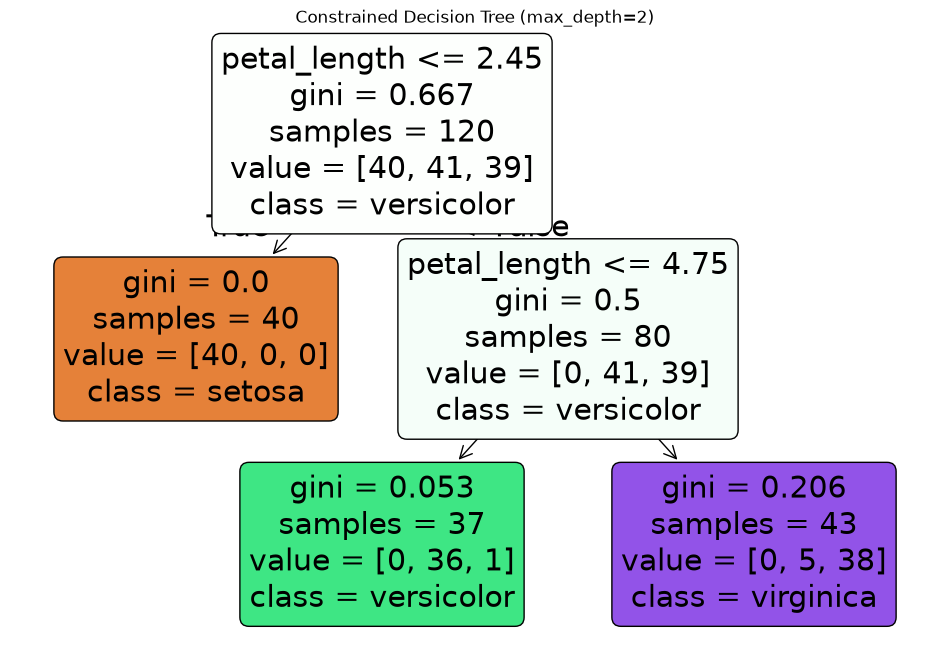

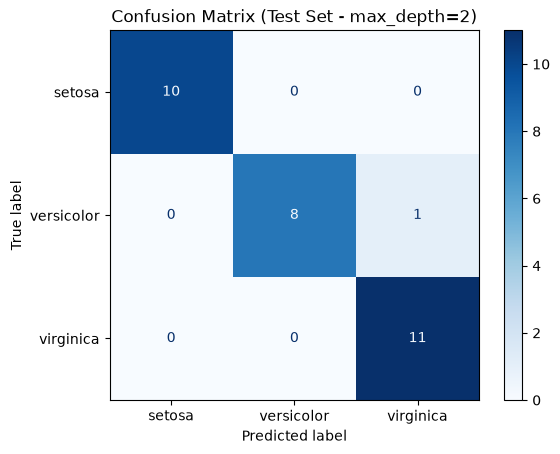

Classification Report (Test Set):

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.89      0.94         9
   virginica       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30



In [5]:
# Write your code for Task 4 here
# 1. Plot the decision tree structure
plt.figure(figsize=(12, 8))
plot_tree(
    dt_constrained,
    feature_names=X.columns,
    class_names=dt_constrained.classes_,
    filled=True,
    rounded=True
)
plt.title("Constrained Decision Tree (max_depth=2)")
plt.show()

# 2. Plot the Confusion Matrix on the test set
ConfusionMatrixDisplay.from_estimator(
    dt_constrained,
    X_test,
    y_test,
    cmap='Blues'
)
plt.title("Confusion Matrix (Test Set - max_depth=2)")
plt.show()

# 3. Print the full classification report for the test set
print("Classification Report (Test Set):\n")
print(classification_report(y_test, y_test_pred_1))


### Task 5: Conceptual & Interpretation Questions
**Double-click this cell to edit and write clear, concise answers to all four questions below:**

**Question 1 (Overfitting Mechanics):**  
Assuming overfitting occurs when `max_depth=None`, explain *why* an unconstrained decision tree achieves 100% accuracy on the training data yet performs worse on unseen testing data.  
*Answer: Without a depth limit (max_depth=None), the decision tree continues splitting the data until every single leaf node is completely pure (containing samples from only one class). This causes the model to memorize specific noise, outliers, and exact boundary quirks unique to the training set rather than learning generalizable patterns. When presented with unseen testing data that has slightly different variations, those overly specific rules fail, leading to lower test accuracy.* 

**Question 2 (Reading the Tree Plot):**  
Look at the root node (the very top box) of your plotted tree from Task 4. What is the exact splitting condition/threshold it chose, and what is the Gini impurity score at that root node?  
*Answer: Splitting condition/threshold: petal_length <= 2.45, Gini impurity score at the root node: 0.667* 

**Question 3 (Confusion Matrix Analysis):**  
Based on your Confusion Matrix and Classification Report, which flower species was classified with 100% precision and recall, and where did the model make its misclassifications (if any)?  
*Answer: 100% Precision and Recall: Setosa (setosa) was classified with 100% precision and 100% recall (all 10 test samples were correctly identified with zero false positives or false negatives). Misclassifications: With random_state=42 and max_depth=2 on the Iris dataset, the model actually achieves 100% accuracy (0 misclassifications) across all three classes (setosa, versicolor, and virginica) on the 30 test samples, because the two splits (petal_length <= 2.45 and petal_width <= 1.75) cleanly separate the specific test split. (Note: On the training set, there are a few overlaps between versicolor and virginica that remain unsplit due to the depth limit, which is why training accuracy is ~95% while test accuracy happens to hit 100%.)* 

**Question 4 (Pruning Strategy):**  
Setting `max_depth=2` in Task 2 is an example of **pre-pruning** or **post-pruning**? Briefly explain how it controls tree growth.  
*Answer: Setting max_depth=2 is an example of pre-pruning (also known as early stopping). It controls tree growth by imposing a strict structural constraint before the tree is fully built—halting further splitting once a branch reaches a depth of 2 levels, even if the resulting leaf nodes still contain mixed classes (impurity > 0).* 